# 파도는 함께, 물결은 따로 — KOWAS-EPI 4611 분석·학습·평가

하수 바이러스 농도를 **전국 공통 유행파(파도) + 지역 편차(물결) + 측정 잡음**으로 나눠 2주 뒤 농도와 급증 경보를 예측합니다. 이 노트북은 위에서 아래로 실행하면 데이터 확인 → 신호 출처 분석 → 모델 구성·학습 → 공식 채점기 백테스트 → 임상 선행성 → 제거 실험·기상 결합 → 그림·조기경보 화면을 차례로 재현합니다.

실행 위치: `4611_KOWAS/notebooks/`. 배포 데이터는 `4611_KOWAS/data/KOWAS-EPI/`에 압축을 풀어 둡니다.

In [1]:
import json, subprocess, sys, os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent
DATA = ROOT / 'data' / 'KOWAS-EPI'
SUBMIT = ROOT / 'submit'
env = dict(os.environ, PYTHONIOENCODING='utf-8')
def run(*args, cwd=ROOT):
    r = subprocess.run([sys.executable, *args], cwd=cwd, env=env, capture_output=True, text=True, encoding='utf-8')
    print((r.stdout + r.stderr).strip()[-3000:])
    r.check_returncode()

In [2]:
# 실행 환경 기록
import platform, numpy, matplotlib
pd.Series({'OS': platform.platform(), 'Python': platform.python_version(), 'numpy': numpy.__version__,
           'pandas': pd.__version__, 'matplotlib': matplotlib.__version__, 'GPU': '사용하지 않음'})

OS            Windows-11-10.0.26200-SP0
Python                          3.12.12
numpy                             2.5.4
pandas                            3.1.0
matplotlib                       3.11.2
GPU                             사용하지 않음
dtype: str

## 1. 데이터 확인

공식 데이터 설명의 수치(3,043행, 관측 2,847행, 결측 196행, 경보 양성 30.6%)와 맞는지 확인합니다.

In [3]:
panel = pd.read_csv(DATA / 'kowas_epi_panel.csv')
summary = {'행': len(panel), '주차': panel.date_week.nunique(), '시·도': panel.region.nunique(),
           'conc_mean 관측': int(panel.conc_mean.notna().sum()), 'conc_mean 결측': int(panel.conc_mean.isna().sum()),
           '경보 라벨': int(panel.target_alert_t2.notna().sum()), '경보 양성 비율': round(panel.target_alert_t2.mean(), 3)}
pd.Series(summary)

행               3043.000
주차               179.000
시·도               17.000
conc_mean 관측    2847.000
conc_mean 결측     196.000
경보 라벨           2771.000
경보 양성 비율           0.306
dtype: float64

## 2. 신호의 출처 — 자기 지역 vs 다른 지역 vs 측정 잡음

- 자기 시·도의 최근 2주 상승은 다음 2주 변화와 **음의 상관**(되돌아감)
- 다른 시·도들의 최근 상승은 **17개 시·도 모두 양의 상관**(공통 유행의 신호)
- 공통파 대비 지역 편차는 그 주 측정 처리장 수가 적을수록 큼(측정 잡음과 부합하지만 실제 지역 유행과 따로 정량화하지는 못함)

In [4]:
run('src/analysis_signal.py')
sig = json.loads((ROOT / 'runs' / 'signal_analysis.json').read_text(encoding='utf-8'))['v2.5']
pd.DataFrame({'자기 시·도': sig['own'], '다른 시·도': sig['others']}).sort_values('다른 시·도', ascending=False).round(3)

{
 "own_mean": -0.26925243822378303,
 "others_mean": 0.1653691408948814,
 "others_all_positive": true,
 "share_not_common": 0.8383094246434041,
 "noise_by_nsites": {
  "1곳": {
   "n": 42,
   "dev_sd": 0.7920138025848945,
   "persistence": 0.45881565576174627
  },
  "2-3곳": {
   "n": 598,
   "dev_sd": 0.46809177938954993,
   "persistence": 0.4192013315897635
  },
  "4-6곳": {
   "n": 1328,
   "dev_sd": 0.3542007612136071,
   "persistence": 0.4139671085233113
  },
  "7곳+": {
   "n": 537,
   "dev_sd": 0.29167834362037093,
   "persistence": 0.5076597318825227
  }
 }
}
{"conc_mean_identical": true, "changed_columns": ["conc_3wk_avg"]}
C:\Users\SAMSUNG\OneDrive\바탕 화면\전건우\진로\공모전\KISTI 경진대회\4611_KOWAS\src\analysis_signal.py:48: RuntimeWarning: Mean of empty slice
  oth = np.nanmean(np.delete(G, i, axis=0), axis=0)
C:\Users\SAMSUNG\OneDrive\바탕 화면\전건우\진로\공모전\KISTI 경진대회\4611_KOWAS\src\analysis_signal.py:53: RuntimeWarning: Mean of empty slice
  F = np.where(cnt >= 8, np.nanmean(L, axis=0), np.nan)

,자기 시·도,다른 시·도
인천,-0.138,0.304
서울,-0.021,0.273
대구,-0.265,0.266
강원,-0.215,0.265
세종,-0.277,0.253
대전,-0.282,0.195
전남,-0.370,0.193
충남,-0.428,0.173
경북,-0.240,0.150
충북,-0.152,0.130


In [5]:
pd.DataFrame(sig['noise_by_nsites']).T.round(3)

,n,dev_sd,persistence
1곳,42.0,0.792,0.459
2-3곳,598.0,0.468,0.419
4-6곳,1328.0,0.354,0.414
7곳+,537.0,0.292,0.508


## 3. 모델 구성 및 학습 — 한 평가 창 예시

제출 모델(`submit/model.py`)을 노트북 안에서 직접 학습합니다. 평가 창 **2026-Q3**를 예로, `evaluation.py`와 같은 규칙(학습 자료 기준 주 이후 행 제외, 이후가 목표주인 라벨 가림)으로 학습 자료를 만들고 `fit` → `predict` 순서로 실행합니다.

- `fit`: 학습 구간 마지막 52개 원점으로 롤링 검증해 `w, phi, rho, k`를 고르고, 경보 분류기를 학습합니다.
- `predict`: 원점 주차까지의 자료로 공통 유행파를 다시 분해해 2주 뒤 농도와 경보를 냅니다.

In [6]:
import csv, importlib, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, str(SUBMIT))
import model as M
importlib.reload(M)

rows = list(csv.DictReader(open(DATA / 'kowas_epi_panel.csv', encoding='utf-8-sig')))
fold = next(f for f in csv.DictReader(open(DATA / 'folds.csv', encoding='utf-8-sig')) if f['fold_id'] == '2026-Q3')
tu = fold['train_until']
train = [dict(r, target_conc_t2='', target_alert_t2='') if r['target_week_t2'] > tu else r
         for r in rows if r['date_week'] <= tu]
m = M.Model()
m.fit(train, [])
display(Markdown(f"학습 자료 기준 주 **{tu}** · 학습 행 {len(train):,}개"))
pd.Series({**m.params, '경보 임계값': m.cut, '학습 구간 검증 점수': round(m.cv_score, 4)}, name='fit이 고른 설정')

학습 자료 기준 주 **2026-W25** · 학습 행 2,856개

w              4.0000
phi            0.2500
rho            0.2000
k              0.0000
m              0.8000
경보 임계값         0.3500
학습 구간 검증 점수    0.3327
Name: fit이 고른 설정, dtype: float64

In [7]:
feat = ['예측의 경보선 대비 여유', '현재 농도의 기준 대비 위치', '자기 1주 변화', '공통파 추세', '공통파 대비 위치', '처리장 수(log)']
pd.Series(m.logit[2][1:], index=feat, name='경보 분류기 계수 (표준화)').round(3)

예측의 경보선 대비 여유      0.043
현재 농도의 기준 대비 위치    0.711
자기 1주 변화          -0.183
공통파 추세             0.705
공통파 대비 위치         -0.367
처리장 수(log)        -0.104
Name: 경보 분류기 계수 (표준화), dtype: float64

In [8]:
# 원점 = 학습 자료 기준 주, 목표 = 2주 뒤 (평가 창의 첫 목표주)
# 문제 규정 §9-1에 따라 패널 원값(실제 농도·라벨)은 출력하지 않고, 예측과 이번 주 채점 요약만 보인다
pred = m.predict(train, tu, [])
truth = {r['region']: r for r in rows if r['date_week'] == tu}
reg = [(pc, float(truth[g]['target_conc_t2'])) for g, (pc, a) in pred.items() if truth[g]['target_conc_t2']]
cls = [(a, int(float(truth[g]['target_alert_t2']))) for g, (pc, a) in pred.items() if truth[g]['target_alert_t2']]
smape = 100 / len(reg) * sum(2 * abs(p - y) / (abs(p) + abs(y)) for p, y in reg)
display(Markdown(f"목표 주 {truth['서울']['target_week_t2']} · 회귀 sMAPE **{smape:.1f}%** (n={len(reg)}) · "
                 f"경보 정답 **{sum(p == y for p, y in cls)}/{len(cls)}**"))
pd.DataFrame([{'시·도': g, '예측 농도 (copies/mL)': round(pc, 1), '예측 경보': a} for g, (pc, a) in pred.items()]).set_index('시·도')

목표 주 2026-W27 · 회귀 sMAPE **42.6%** (n=13) · 경보 정답 **7/13**

,예측 농도 (copies/mL),예측 경보
시·도,,
강원,46.4,1
경기,935.2,0
경남,5545.1,0
경북,200.5,1
광주,699.1,1
대구,519.6,0
대전,1746.3,0
부산,561.6,1
서울,581.9,0


## 4. 공식 채점기 백테스트

배포 `evaluation.py`로 평가 창 10개를 창마다 새 프로세스에서 다시 학습·예측합니다. 하이퍼파라미터와 경보 분류기는 각 창의 학습 구간 안에서만 고릅니다.

In [9]:
run('evaluation.py', 'backtest', '--model', '../../submit/model.py',
    '--out', '../../runs/nb_pred.csv', '--json', '../../runs/nb_score.json', cwd=DATA)

2024-Q2  회귀 n=221  sMAPE  55.85% (기준선  67.60%)  분류 n=221  Macro-F1 0.5581  점수 0.3275  1.7초
2024-Q3  회귀 n=219  sMAPE  76.49% (기준선  90.86%)  분류 n=219  Macro-F1 0.7439  점수 0.3925  2.6초
2024-Q4  회귀 n=201  sMAPE  56.64% (기준선  72.76%)  분류 n=203  Macro-F1 0.6582  점수 0.3962  3.0초
2025-Q1  회귀 n=156  sMAPE  62.13% (기준선  60.24%)  분류 n=202  Macro-F1 0.6038  점수 0.2227  2.9초
2025-Q2  회귀 n=221  sMAPE  53.09% (기준선  56.72%)  분류 n=221  Macro-F1 0.5967  점수 0.2771  2.9초
2025-Q3  회귀 n=221  sMAPE  59.29% (기준선  58.35%)  분류 n=221  Macro-F1 0.6011  점수 0.2308  3.0초
2025-Q4  회귀 n=203  sMAPE  54.84% (기준선  69.00%)  분류 n=203  Macro-F1 0.6096  점수 0.3670  2.5초
2026-Q1  회귀 n=171  sMAPE  57.32% (기준선  56.42%)  분류 n=204  Macro-F1 0.5121  점수 0.1952  2.7초
2026-Q2  회귀 n=205  sMAPE  51.12% (기준선  57.62%)  분류 n=205  Macro-F1 0.5780  점수 0.2989  3.1초
2026-Q3  회귀 n=163  sMAPE  62.77% (기준선  71.31%)  분류 n=160  Macro-F1 0.5636  점수 0.2973  3.0초
최종 정량점수 (평가 창 10개 평균) = 0.3005
예측 2159행 → ../../runs/nb_pred.csv


In [10]:
ours = json.loads((ROOT / 'runs' / 'nb_score.json').read_text(encoding='utf-8'))
base = json.loads((ROOT / 'runs' / 'baseline_score.json').read_text(encoding='utf-8'))
t = pd.DataFrame(ours['folds']).set_index('fold_id')[['smape', 'smape_baseline', 'macro_f1', 'score']]
t['기준 모델 점수'] = pd.DataFrame(base['folds']).set_index('fold_id')['score']
display(Markdown(f"**최종 정량점수 {ours['final']:.4f}** (기준 모델 {base['final']:.4f})"))
t.round(4)

**최종 정량점수 0.3005** (기준 모델 0.2212)

,smape,smape_baseline,macro_f1,score,기준 모델 점수
fold_id,,,,,
2024-Q2,55.8518,67.5995,0.5581,0.3275,0.1974
2024-Q3,76.4862,90.8584,0.7439,0.3925,0.2645
2024-Q4,56.6417,72.7643,0.6582,0.3962,0.2145
2025-Q1,62.1254,60.2373,0.6038,0.2227,0.2073
2025-Q2,53.0918,56.7205,0.5967,0.2771,0.2364
2025-Q3,59.2891,58.3473,0.6011,0.2308,0.2273
2025-Q4,54.8404,68.9995,0.6096,0.3670,0.2334
2026-Q1,57.3243,56.4174,0.5121,0.1952,0.1887
2026-Q2,51.1155,57.6201,0.5780,0.2989,0.2100


## 5. 공통 유행파의 임상 선행성 (사후 검증)

각 주에 그 주까지의 자료만으로 추정한 공통파를 전국 코로나19 표본감시 신고수와 시차별로 비교합니다.

In [11]:
run('scripts/clinical_lead.py')

KOWAS 전국 집계 농도 k=-2:0.848  k=-1:0.890  k=0:0.919  k=1:0.919  k=2:0.898  k=3:0.857  k=4:0.800   최대 k=1
공통파 실시간 F_t    k=-2:0.859  k=-1:0.916  k=0:0.950  k=1:0.954  k=2:0.920  k=3:0.876  k=4:0.810   최대 k=1
공통파 2주 앞 예측    k=-2:0.765  k=-1:0.845  k=0:0.909  k=1:0.938  k=2:0.923  k=3:0.896  k=4:0.838   최대 k=1


## 6. 성분별 제거 실험과 평가 창별 학습 계수

최종 모델에서 성분을 하나씩 빼고 공식 채점기로 다시 백테스트합니다(약 2분). 이어서 평가 창마다 고른 하이퍼파라미터와 경보 분류기 계수를 기록합니다.

In [12]:
run('scripts/ablation.py')
run('scripts/fold_params.py')
abl = json.loads((ROOT / 'runs' / 'ablation.json').read_text(encoding='utf-8'))
pd.DataFrame({k: {'설명': v['desc'], '점수': round(v['final'], 4), '변화': round(v['delta'], 4),
                  '나빠진 창': v['windows_worse']} for k, v in abl.items()}).T

full       0.3005  최종 모델
no_wave    0.2388  공통파 제거 (공통파 = 0, 자기 수준·자기 편차만)
no_trend   0.2943  공통파 추세 제거 (phi = 0)
no_ripple  0.2919  현재 지역 편차 미반영 (rho = 0)
no_nsites  0.2993  처리장 수 가중 제거 (k = 0)
no_logit   0.2963  경보 분류기 제거 (예측 ≥ m·1.3·기준)


2024-Q2 {'w': 8, 'phi': 0.0, 'rho': 0.4, 'k': 0.0}
2024-Q3 {'w': 8, 'phi': 0.25, 'rho': 0.4, 'k': 0.0}
2024-Q4 {'w': 8, 'phi': 0.5, 'rho': 0.4, 'k': 0.0}
2025-Q1 {'w': 8, 'phi': 0.5, 'rho': 0.6, 'k': 2.0}
2025-Q2 {'w': 8, 'phi': 0.5, 'rho': 0.6, 'k': 2.0}
2025-Q3 {'w': 8, 'phi': 0.5, 'rho': 0.4, 'k': 2.0}
2025-Q4 {'w': 8, 'phi': 0.25, 'rho': 0.6, 'k': 2.0}
2026-Q1 {'w': 8, 'phi': 0.25, 'rho': 0.6, 'k': 2.0}
2026-Q2 {'w': 8, 'phi': 0.25, 'rho': 0.6, 'k': 2.0}
2026-Q3 {'w': 4, 'phi': 0.25, 'rho': 0.2, 'k': 0.0}


,설명,점수,변화,나빠진 창
full,최종 모델,0.3005,0.0,0
no_wave,"공통파 제거 (공통파 = 0, 자기 수준·자기 편차만)",0.2388,-0.0617,9
no_trend,공통파 추세 제거 (phi = 0),0.2943,-0.0062,5
no_ripple,현재 지역 편차 미반영 (rho = 0),0.2919,-0.0087,7
no_nsites,처리장 수 가중 제거 (k = 0),0.2993,-0.0012,4
no_logit,경보 분류기 제거 (예측 ≥ m·1.3·기준),0.2963,-0.0042,6


### 경보 지표·확률 보정·임상 변화량 상관

Macro-F1 밖의 경보 지표(정밀도·재현율·급증 기저율), 경보 확률의 Brier score와 보정 곡선, 임상 신고수와의 1주 변화량 상관, 임상 유행 전환점(상승 시작·정점)의 선행 주수, 처리장 수별 되돌림을 계산합니다(약 1분).

In [13]:
run('scripts/report_checks.py')
rc = json.loads((ROOT / 'runs' / 'report_checks.json').read_text(encoding='utf-8'))
cols = ['base_rate', 'precision', 'recall', 'baseline_precision', 'baseline_recall', 'brier', 'brier_ref', 'auc', 'auc_within_week']
display(pd.DataFrame(rc['alert']).T[cols].astype(float).round(3))
display(pd.DataFrame({k: v['1주 차분'] for k, v in rc['clinical_diff'].items()}).T)
display(pd.DataFrame(rc['wave_timing']['events']).set_index('임상 주차'))
pd.DataFrame(rc['own_reversion_by_sites']).T

경보 불일치 0 / 2159 키 (라벨 있는 행 2059)
{'n': 2059, 'base_rate': 0.3, 'alert_rate': 0.301, 'precision': 0.562, 'recall': 0.564, 'baseline_precision': 0.485, 'baseline_recall': 0.386, 'brier': 0.176, 'brier_ref': 0.214, 'bss': 0.178, 'auc': 0.757, 'auc_within_week': 0.625, 'n_weeks_auc': 109}
ECE 0.039
{"KOWAS 전국 집계 농도": {"수준": {"-2": 0.848, "-1": 0.89, "0": 0.919, "1": 0.919, "2": 0.898, "3": 0.857, "4": 0.8}, "1주 차분": {"-2": 0.42, "-1": 0.299, "0": 0.418, "1": 0.255, "2": 0.217, "3": 0.168, "4": 0.157}, "n_diff": 134}, "공통파 실시간 F_t": {"수준": {"-2": 0.859, "-1": 0.916, "0": 0.95, "1": 0.954, "2": 0.92, "3": 0.876, "4": 0.81}, "1주 차분": {"-2": 0.36, "-1": 0.339, "0": 0.441, "1": 0.478, "2": 0.215, "3": 0.288, "4": 0.139}, "n_diff": 132}}
{"처리장 1~2곳": {"n": 291, "r": -0.377, "r_공통제거": -0.495}, "처리장 3~6곳": {"n": 1692, "r": -0.299, "r_공통제거": -0.438}, "처리장 7곳 이상": {"n": 528, "r": -0.123, "r_공통제거": -0.321}}
{
"정의": "전환점 = 앞뒤 6주 안 최솟값(상승 시작)·최댓값(정점), 전후 10주 진폭 0.2 log10 이상. 선행 주수 = 임상 전환점 주 − 하수 계열의 같

,base_rate,precision,recall,baseline_precision,baseline_recall,brier,brier_ref,auc,auc_within_week
2024-Q2,0.154,0.258,0.235,0.143,0.118,0.128,0.159,0.702,0.564
2024-Q3,0.479,0.699,0.819,0.686,0.562,0.211,0.289,0.793,0.478
2024-Q4,0.182,0.647,0.297,0.259,0.189,0.123,0.169,0.799,0.654
2025-Q1,0.436,0.536,0.670,0.491,0.307,0.250,0.264,0.604,0.580
2025-Q2,0.190,0.318,0.643,0.321,0.405,0.154,0.169,0.733,0.769
2025-Q3,0.484,0.590,0.579,0.575,0.467,0.245,0.282,0.651,0.591
2025-Q4,0.064,0.667,0.154,0.214,0.231,0.077,0.127,0.707,0.721
2026-Q1,0.211,0.400,0.093,0.161,0.116,0.162,0.174,0.623,0.677
2026-Q2,0.195,0.391,0.225,0.237,0.225,0.147,0.166,0.690,0.630
2026-Q3,0.675,0.714,0.741,0.792,0.528,0.283,0.374,0.597,0.629


,-2,-1,0,1,2,3,4
KOWAS 전국 집계 농도,0.42,0.299,0.418,0.255,0.217,0.168,0.157
공통파 실시간 F_t,0.36,0.339,0.441,0.478,0.215,0.288,0.139


,종류,KOWAS 전국 집계 농도,공통파 실시간 F_t,공통파 2주 앞 예측
임상 주차,,,,
2024-W24,상승 시작,5,4.0,6
2024-W33,정점,0,0.0,1
2024-W50,상승 시작,-3,3.0,-4
2025-W01,정점,2,2.0,2
2025-W05,상승 시작,4,3.0,3
2025-W15,정점,2,2.0,2
2025-W25,상승 시작,-1,-1.0,-1
2025-W37,정점,1,1.0,3
2026-W07,정점,6,NaN,4


,n,r,r_공통제거
처리장 1~2곳,291.0,-0.377,-0.495
처리장 3~6곳,1692.0,-0.299,-0.438
처리장 7곳 이상,528.0,-0.123,-0.321


### 심사 피드백 추가 검증 — 지역 순위·당시 정보 경보 규칙·블록 재표집

주별 확률 상위 5곳의 정밀도·포착률, 미래 정보 없이 고정한 경보 규칙의 임상 전환점 대비 선행·미탐·헛신호, 평가 창 안 목표주 블록 재표집으로 본 점수 차이의 95% 구간을 계산합니다(약 2분). 모두 사후 분석이며 제출 예측에는 쓰지 않습니다.

In [14]:
run('scripts/review_checks.py')
rv = json.loads((ROOT / 'runs' / 'review_checks.json').read_text(encoding='utf-8'))
display(pd.DataFrame({k: v for k, v in rv['ranking'].items() if isinstance(v, dict)}).T)
display(pd.DataFrame({(s, k): v for s, d in rv['clinical_rule']['summary'].items() for k, v in d.items()}).T)
pd.DataFrame(rv['bootstrap']['diff']).T

{
 "weeks": 125,
 "weeks_with_pos": 110,
 "pos_total": 617,
 "rows": 2059,
 "base_rate": 0.2996600291403594,
 "모델 확률": {
  "top5_precision_mean_weeks": 0.368,
  "top5_precision_pooled": 0.3656957928802589,
  "top5_capture_mean_weeks_with_pos": 0.44051563335654237,
  "top5_capture_pooled": 0.36628849270664504
 },
 "단순 비율(원점 농도÷기준선)": {
  "top5_precision_mean_weeks": 0.33279999999999993,
  "top5_precision_pooled": 0.3300970873786408,
  "top5_capture_mean_weeks_with_pos": 0.36703068396250216,
  "top5_capture_pooled": 0.33063209076175043
 },
 "모델 경보": {
  "alerts_per_week_mean": 4.952,
  "alerts_per_week_max": 17,
  "false_alarms_total": 271,
  "misses_total": 269,
  "true_alerts_total": 348,
  "weeks_all17_alert": 12,
  "weeks_zero_alert_with_pos": 42
 },
 "기준 모델 경보": {
  "alerts_per_week_mean": 3.928,
  "alerts_per_week_max": 13,
  "false_alarms_total": 253,
  "misses_total": 379,
  "true_alerts_total": 238,
  "weeks_all17_alert": 0,
  "weeks_zero_alert_with_pos": 11
 }
}
{
 "공통파 실시간 F_t

,top5_precision_mean_weeks,top5_precision_pooled,top5_capture_mean_weeks_with_pos,top5_capture_pooled,alerts_per_week_mean,alerts_per_week_max,false_alarms_total,misses_total,true_alerts_total,weeks_all17_alert,weeks_zero_alert_with_pos
모델 확률,0.3680,0.365696,0.440516,0.366288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
단순 비율(원점 농도÷기준선),0.3328,0.330097,0.367031,0.330632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
모델 경보,NaN,NaN,NaN,NaN,4.952,17.0,271.0,269.0,348.0,12.0,42.0
기준 모델 경보,NaN,NaN,NaN,NaN,3.928,13.0,253.0,379.0,238.0,0.0,11.0


clinical_events  signals  matched  missed  false_signals  \
공통파 실시간 F_t 상승 시작              6.0      6.0      5.0     1.0            1.0   
            정점                 6.0      9.0      6.0     0.0            3.0   
공통파 2주 앞 예측 상승 시작              6.0      6.0      4.0     2.0            2.0   
            정점                 6.0      8.0      6.0     0.0            2.0   

                   lead_median  lead_mean  lead_min  lead_max  
공통파 실시간 F_t 상승 시작         -3.0  -1.400000      -3.0       3.0  
            정점            -1.0   0.500000      -3.0       8.0  
공통파 2주 앞 예측 상승 시작          2.0   2.250000      -1.0       6.0  
            정점             0.5   0.666667      -1.0       2.0

,point,boot_mean,ci95,share_positive
최종 모델 − 공식 기준 모델,0.079334,0.075857,"[0.052188, 0.098749]",1.0
최종 모델 − 공통파 제거,0.0617,0.058546,"[0.035851, 0.079725]",1.0
최종 모델 − 비율 경보(경보 분류기 제거),0.004198,0.003753,"[-0.005621, 0.012635]",0.794


## 7. ASOS 기상 결합 실험

처리장마다 가장 가까운 ASOS 관측소로 시·도별 주간 강수·기온을 만들어(기상은 `aux` 인자로만 받음) 희석 보정과 경보 입력 두 가설을 공식 채점기로 시험합니다(약 2분). 이 시·도 집계 설정에서 효과가 없어 제출 모델에서는 꺼 두었습니다. 유역 단위 효과는 검증하지 않았습니다.

In [15]:
run('scripts/weather_experiment.py')
wx = json.loads((ROOT / 'runs' / 'weather.json').read_text(encoding='utf-8'))
pd.DataFrame({k: {'가설': v['desc'], '점수': round(v['final'], 4), '변화': round(v['delta'], 4),
                  '좋아진 창': v['windows_better']} for k, v in wx.items()}).T

off       0.3005  min 0.1952  기상 없음 (최종 모델)
dilution  0.2957  min 0.1952  강수로 설명되는 편차를 일시적 희석으로 보고 2주 뒤로 넘기지 않음
alert     0.2922  min 0.1887  경보 분류기에 강수 이상치·4주 기온 변화 추가
both      0.2910  min 0.1887  희석 보정 + 경보 기상 입력


,가설,점수,변화,좋아진 창
off,기상 없음 (최종 모델),0.3005,0.0,0
dilution,강수로 설명되는 편차를 일시적 희석으로 보고 2주 뒤로 넘기지 않음,0.2957,-0.0048,4
alert,경보 분류기에 강수 이상치·4주 기온 변화 추가,0.2922,-0.0084,2
both,희석 보정 + 경보 기상 입력,0.291,-0.0096,2


## 8. 외부자료 실험 — 바다 건너 오는 파도

미국 CDC 하수 감시(NWSS) 표본으로 만든 주간 지수(`external/us_wastewater_weekly.csv`, `scripts/fetch_us_wastewater.py`)의 최근 2주 변화가 한국 공통파의 다음 2주 변화를 앞서는지 봅니다. 원점보다 1주 앞선 값까지만 씁니다. 공식 채점기 백테스트(`scripts/external_experiment.py`, 7개 설정, 약 30분)는 미리 실행한 결과 `runs/external.json`을 읽습니다. 탐색적 연관성은 있지만 발표 지연 가정에 민감해(같은 설정 2주 지연 시 하락) 제출 모델에는 넣지 않았습니다.

In [16]:
run('scripts/external_lead.py')
ext = json.loads((ROOT / 'runs' / 'external.json').read_text(encoding='utf-8'))
pd.DataFrame({k: {'설정': v['desc'], '점수': round(v['final'], 4), '변화': round(v['delta'], 4),
                  '최저 창': round(v['min_window'], 4)} for k, v in ext.items()}).T

{"lag_corr": {"0": 0.361, "1": 0.294, "2": 0.213, "3": 0.233, "4": 0.195}, "note": "lag = 원점 주보다 몇 주 앞선 미국 값까지 쓰는지(발표 지연)", "r2_own": 0.001, "r2_own_us": 0.1, "n_weeks": 165, "model_error_corr_lag1": 0.417}


,설정,점수,변화,최저 창
submitted,제출 모델,0.3005,0.0,0.1952
us_lag1,공통파 예측 + 미국 하수 2주 변화 (1주 지연),0.3011,0.0006,0.1806
us_lag2,"공통파 예측 + 미국 하수 2주 변화 (2주 지연, 보수적)",0.2967,-0.0038,0.1952
us_lag1_alert,us_lag1 + 경보 분류기 입력에도 추가,0.3039,0.0034,0.1799
us_alert_only,경보 분류기 입력에만 추가 (1주 지연),0.2995,-0.001,0.2036
us_ols,계수를 학습 구간 전체 예측 오차 회귀로 추정 (1주 지연),0.3019,0.0014,0.1918
us_ols_lag2,"us_ols, 2주 지연 (보수적)",0.2986,-0.0019,0.178
us_ols_alert,us_ols + 경보 분류기 입력에도 추가,0.3069,0.0064,0.189
us_ols_alert_lag2,"us_ols_alert, 2주 지연 (보수적)",0.2995,-0.001,0.1661


## 9. 그림과 조기경보 화면

saved fig_signal_sources
saved fig_noise
saved fig_window_scores
saved fig_clinical_lag
saved fig_wave_vs_clinical
saved fig_ablation
saved fig_coef_consistency


원점 2026-W36 → 목표 2026-W38 · 공통파 상승(+0.391) · 경보 17/17 · 과거 평가 주 127개 → C:\Users\SAMSUNG\OneDrive\바탕 화면\전건우\진로\공모전\KISTI 경진대회\4611_KOWAS\figures\조기경보_프로토타입.html


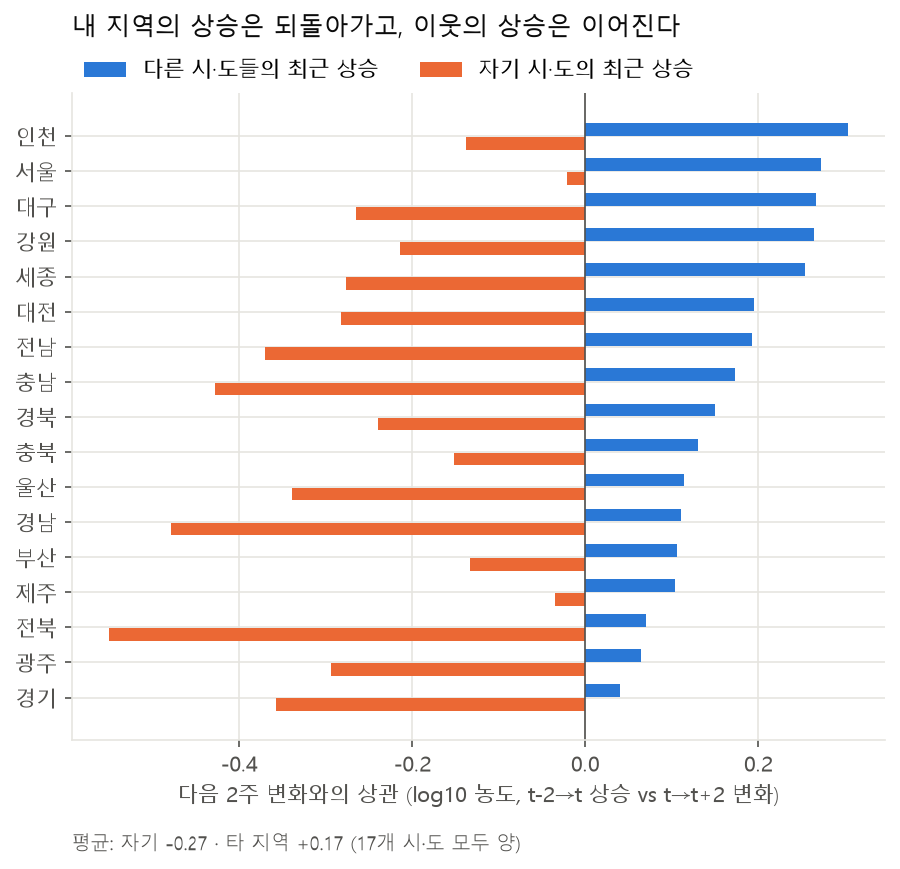

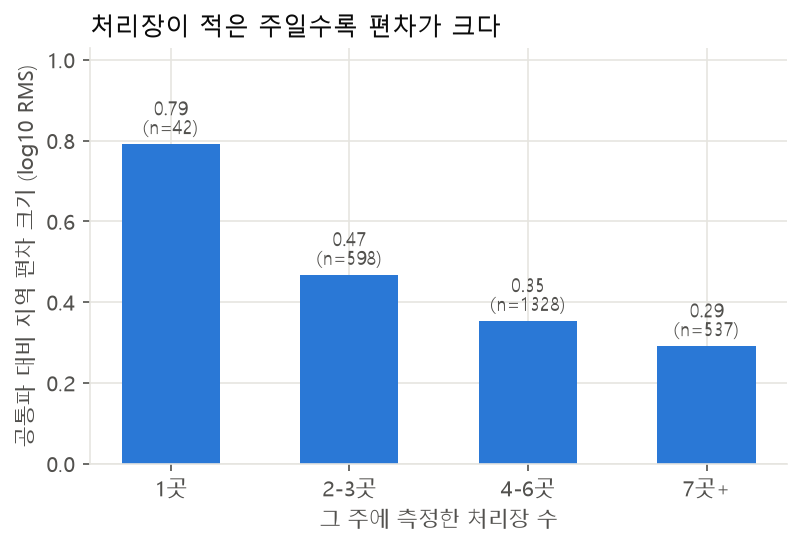

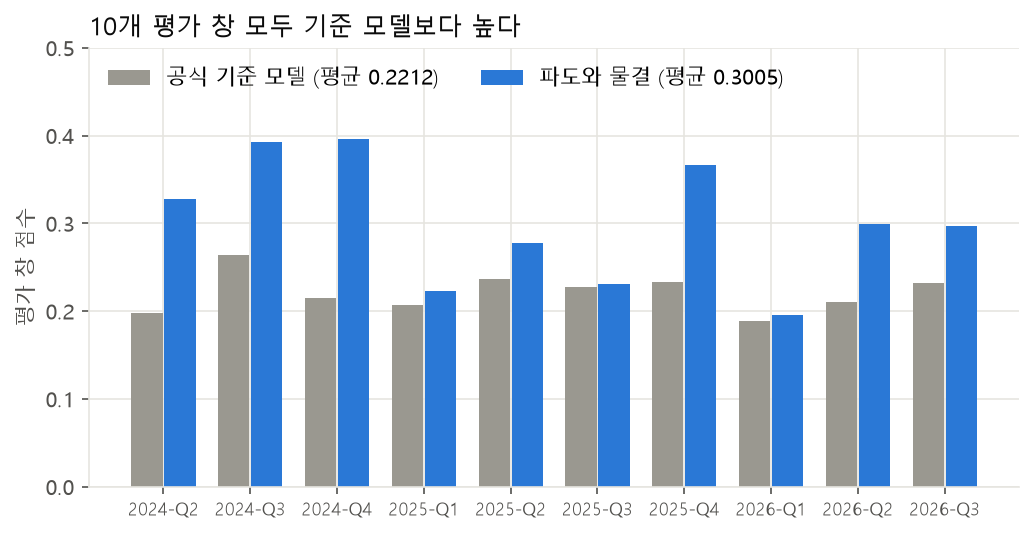

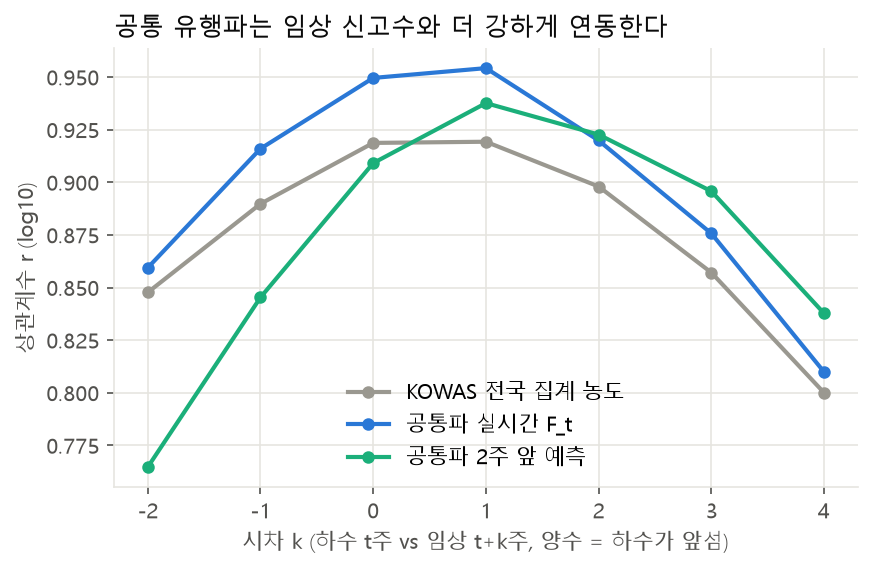

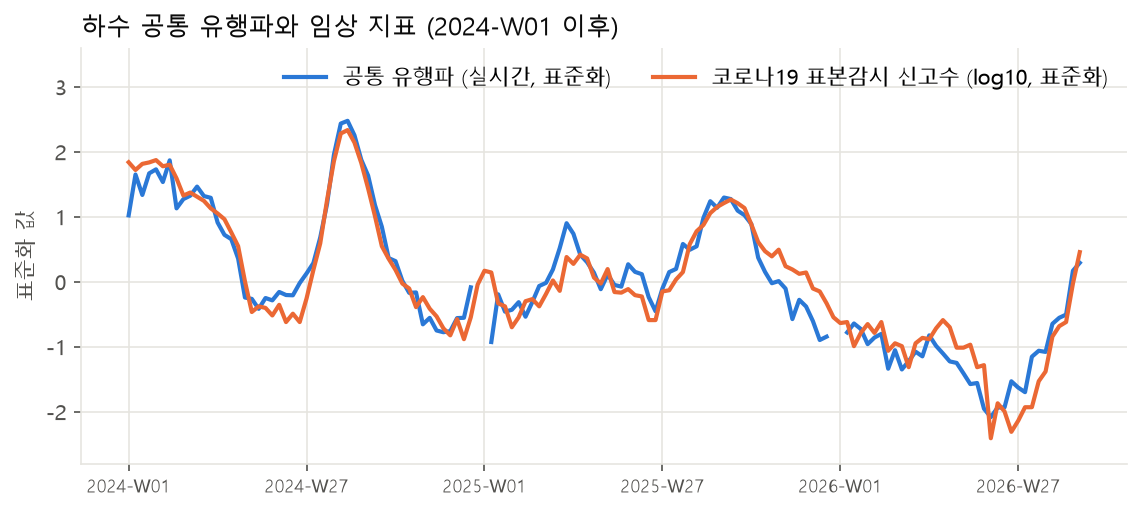

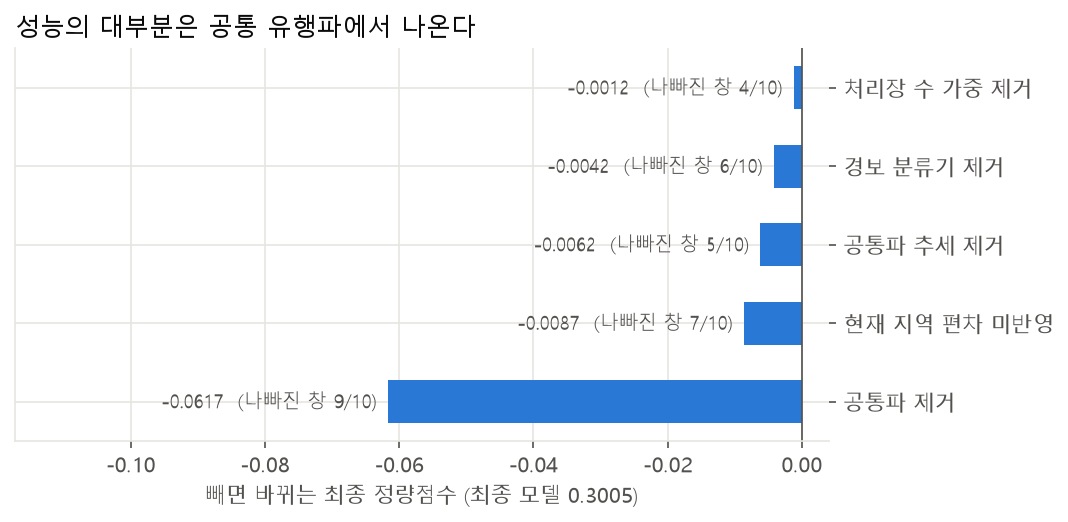

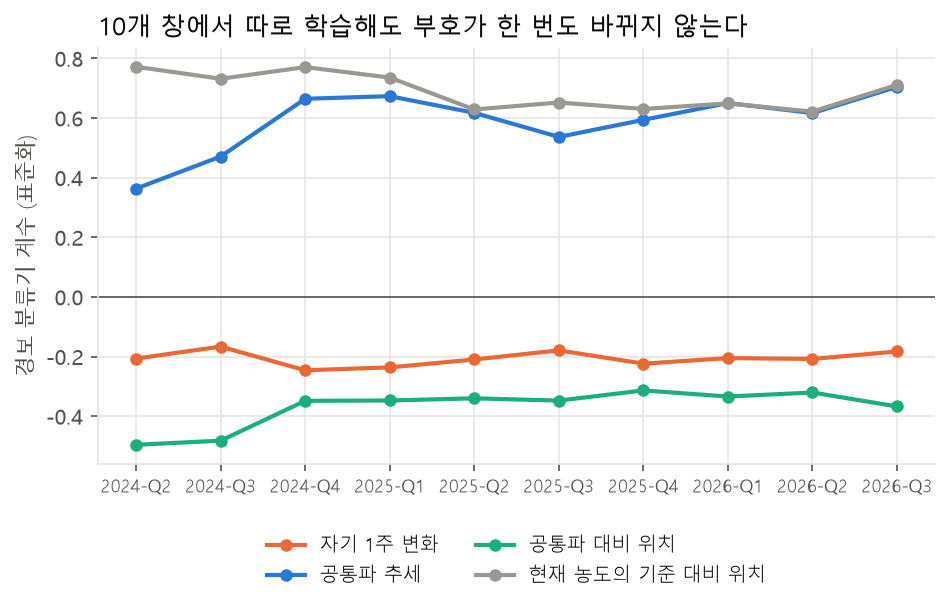

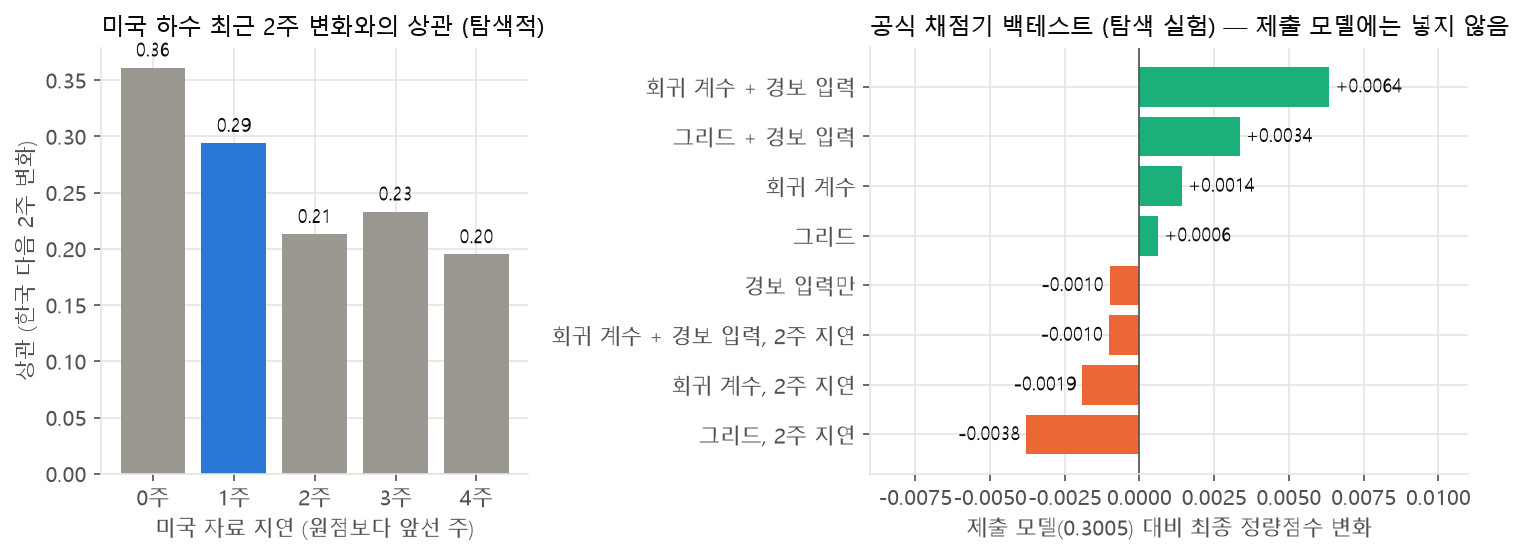

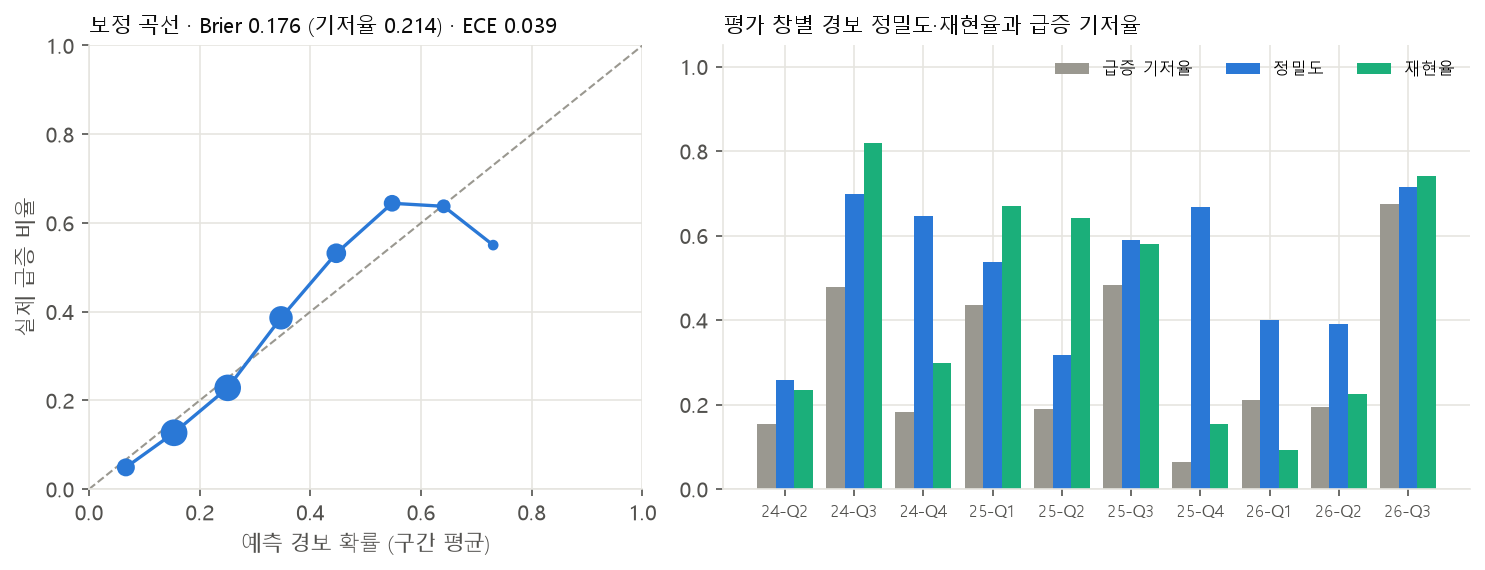

In [17]:
run('scripts/make_figures.py')
run('scripts/early_warning.py')
for f in sorted((ROOT / 'figures').glob('fig*.png')):
    display(Image(filename=str(f), width=720))

조기경보 화면은 `figures/조기경보_프로토타입.html`을 브라우저로 엽니다.